# 1c — Grille de score · Segment : Comptes joints

**Objectif** : dérouler le chapitre 6 du cours : transformer le modèle du notebook `1b` en une grille de points, sans
modifier son pouvoir discriminant.

| § | Thème | Traitement appliqué ici |
|---|-------|-------------------------|
| 6.1 | Sortie du modèle | score linéaire, probabilité ; toute transformation monotone conserve le classement |
| 6.2 | Méthode du PDO | Offset / Factor, points additifs par modalité |
| 6.3 | Normalisation des coefficients | grille sur 1000 points, contributions CTR et q |
| 6.4 | Comparaison | même classement, même q, lectures métier différentes |

> Ce notebook est un **rapport lisible** : les calculs sont délégués à `utils/scorecard.py`.

## 0. Imports et configuration

In [1]:
import sys, json
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from utils.modele import ModeleLogit, appliquer_fusions, performance
from utils.scorecard import (
    offset_factor, grille_pdo, grille_normalisation, contributions, parts_classes, noter,
    plot_grille, plot_distribution_score,
)
from utils.exploration import exporter_excel

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(60)

polars.config.Config

### Paramètres d'échelle (convention, cours 6.2.3)

| Paramètre | Valeur | Lecture |
|-----------|--------|---------|
| `POINTS0` | 600 | score de référence |
| `ODDS0` | 50 | à 600 points, 50 bons pour 1 mauvais (convention de Siddiqi) |
| `PDO` | 20 | 20 points de plus doublent les odds de bon |
| `TOTAL` | 1000 | étendue de la grille par normalisation (6.3) |

Ce sont des choix d'échelle, sans justification statistique propre (« comme le choix des unités d'un thermomètre »).

In [2]:
BASE_CL   = ROOT / "data/segments/joint/base_joint_classes.parquet"
MODELE    = ROOT / "outputs/modele/modele_joint.json"
SORTIE    = ROOT / "outputs/scorecard/grille_joint.json"
SORTIE_XLS = ROOT / "outputs/scorecard/grille_joint.xlsx"

TARGET = "ddefaut_ndb"

POINTS0, ODDS0, PDO = 600, 50, 20
TOTAL = 1000

## 1. Chargement du modèle et des données

In [3]:
m = json.loads(MODELE.read_text(encoding="utf-8"))
VARS = m["variables"]
FUSIONS = {v: {int(a): b for a, b in f.items()} for v, f in m["fusions"].items()}
coefs = pl.DataFrame(m["coefficients"])
beta0 = m["beta0"]

df = appliquer_fusions(pl.read_parquet(BASE_CL), FUSIONS)
df_app  = df.filter(pl.col("echantillon") == "apprentissage")
df_test = df.filter(pl.col("echantillon") == "test")

# Score linéaire S = β0 + Σ β_jk, recalculé à partir des coefficients exportés
def score_lineaire(d):
    return beta0 + pl.sum_horizontal(
        pl.col(v).cast(pl.Int64).replace_strict(
            dict(zip(*coefs.filter(pl.col("variable") == v).select("classe", "beta").to_dict(as_series=False).values())),
            default=None, return_dtype=pl.Float64)
        for v in VARS)

df_app  = df_app.with_columns(S=score_lineaire(df_app))
df_test = df_test.with_columns(S=score_lineaire(df_test))
print(f"{len(VARS)} variables, {coefs.height} modalités | β0 = {beta0:.3f}")

5 variables, 16 modalités | β0 = -8.248


## 6.1 Sortie du modèle : score linéaire et probabilité

Le modèle produit un score linéaire S = β0 + Σ β_jk (logit), transformé en probabilité par p = 1 / (1 + e^−S). La
fonction logistique étant strictement croissante, le classement est le même sur S et sur p : seul l'**ordonnancement**
compte à ce stade, la probabilité sera calibrée au chapitre 8.

In [4]:
resume = df_app.with_columns(p=1 / (1 + (-pl.col("S")).exp())).select(
    pl.col("S").min().alias("S_min"), pl.col("S").median().alias("S_mediane"), pl.col("S").max().alias("S_max"),
    pl.col("p").min().alias("p_min"), pl.col("p").median().alias("p_mediane"), pl.col("p").max().alias("p_max"),
    pl.col("p").mean().alias("p_moyenne"), pl.col(TARGET).mean().alias("taux_defaut_observe"),
)
resume

S_min,S_mediane,S_max,p_min,p_mediane,p_max,p_moyenne,taux_defaut_observe
f64,f64,f64,f64,f64,f64,f64,f64
-8.248397,-6.845651,-1.819954,0.000262,0.001063,0.139439,0.004835,0.004835


## 6.2 Méthode du PDO

Factor = PDO / ln 2 et Offset = Points₀ − Factor · ln(odds₀). Les points de chaque modalité valent

  **Points_jk = (Offset − Factor · β0) / p − Factor · β_jk**

La classe de référence (β = 0) reçoit (Offset − Factor·β0)/p points dans toutes les variables ; les points baissent
quand le risque monte.

**Point de vigilance β0 (cours 6.2.3)** : β0 n'a pas à être corrigé ici. La base n'a pas été rééquilibrée : le tirage
a pris la même fraction des sains et des défauts (notebook 0, § 1.2), donc β0 est consistant et l'ancrage
« 600 points ↔ 50:1 » est lisible sur la population. Il reste une lecture illustrative : la PD sera calibrée sur les
classes de risque (ch. 8), jamais lue sur l'échelle de points.

In [5]:
offset, factor = offset_factor(POINTS0, ODDS0, PDO)
print(f"Factor = {factor:.3f} | Offset = {offset:.2f} | points de la classe de référence = "
      f"{(offset - factor * beta0) / len(VARS):.1f} par variable")

grille_1 = grille_pdo(coefs, beta0, POINTS0, ODDS0, PDO, arrondi=True)
with pl.Config(tbl_rows=-1):
    display(grille_1)

Factor = 28.854 | Offset = 487.12 | points de la classe de référence = 145.0 par variable


variable,classe,beta,points
str,i64,f64,f64
"""MINSOLDE_PAR""",1,0.0,145.0
"""MINSOLDE_PAR""",2,0.790501,122.0
"""MINSOLDE_PAR""",3,0.814934,122.0
"""MINSOLDE_PAR""",4,1.025436,115.0
"""solde_crediteur""",1,0.0,145.0
"""solde_crediteur""",2,0.653838,126.0
"""solde_crediteur""",3,0.912018,119.0
"""solde_crediteur""",4,1.501497,102.0
"""CRTAD_AG_NBJDE_BA""",1,0.0,145.0


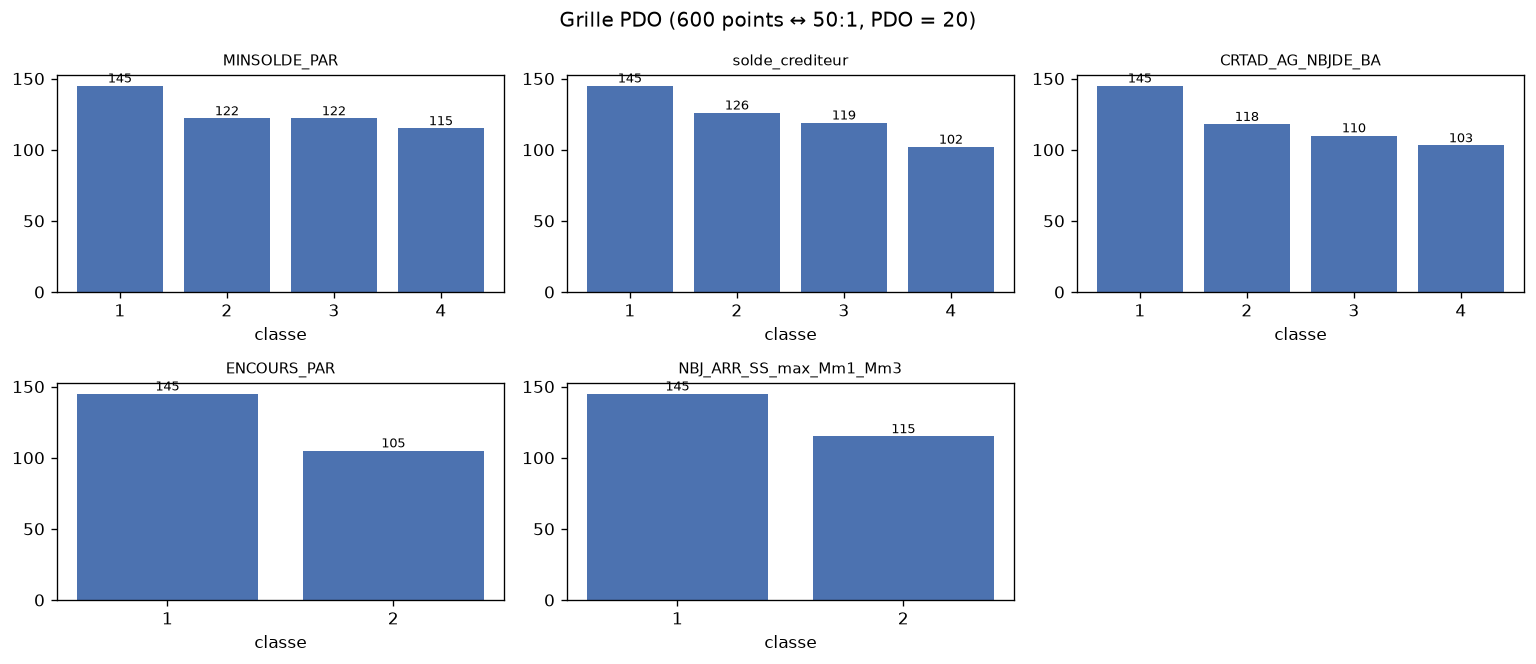

In [6]:
fig = plot_grille(grille_1, titre=f"Grille PDO ({POINTS0} points ↔ {ODDS0}:1, PDO = {PDO})")
plt.show()

## 6.3 Grille par normalisation des coefficients (1000 points)

SC(j,k) = 1000 × (R_j − β_jk) / Σ_v R_v, avec R_j = max_k β_jk : la modalité la plus risquée de chaque variable vaut 0,
un dossier dans la meilleure classe de toutes les variables obtient 1000.

- **CTR_j** = note maximale de la variable / 10 : part de l'échelle que la variable peut expliquer au maximum ;
- **q_j** = σ_j / Σ σ_v : part de la variable dans la **dispersion réelle** des scores du portefeuille (σ_j pondéré par
  les effectifs des classes, mesuré sur l'apprentissage).

In [7]:
grille_2 = grille_normalisation(coefs, TOTAL, arrondi=True)
with pl.Config(tbl_rows=-1):
    display(grille_2)

variable,classe,beta,points
str,i64,f64,f64
"""MINSOLDE_PAR""",1,0.0,160.0
"""MINSOLDE_PAR""",2,0.790501,37.0
"""MINSOLDE_PAR""",3,0.814934,33.0
"""MINSOLDE_PAR""",4,1.025436,0.0
"""solde_crediteur""",1,0.0,234.0
"""solde_crediteur""",2,0.653838,132.0
"""solde_crediteur""",3,0.912018,92.0
"""solde_crediteur""",4,1.501497,0.0
"""CRTAD_AG_NBJDE_BA""",1,0.0,226.0


In [8]:
parts = parts_classes(df_app, VARS)
contrib = contributions(grille_normalisation(coefs, TOTAL), parts, TOTAL)
contrib

variable,note_max,moyenne,sigma,CTR,q
str,f64,f64,f64,f64,f64
"""ENCOURS_PAR""",218.209265,152.740933,99.998471,21.820927,0.287193
"""CRTAD_AG_NBJDE_BA""",226.356588,153.647057,91.910904,22.635659,0.263966
"""solde_crediteur""",233.57079,172.599301,76.486217,23.357079,0.219666
"""MINSOLDE_PAR""",159.515426,118.580233,63.168859,15.951543,0.181419
"""NBJ_ARR_SS_max_Mm1_Mm3""",162.347931,160.626539,16.628327,16.234793,0.047756


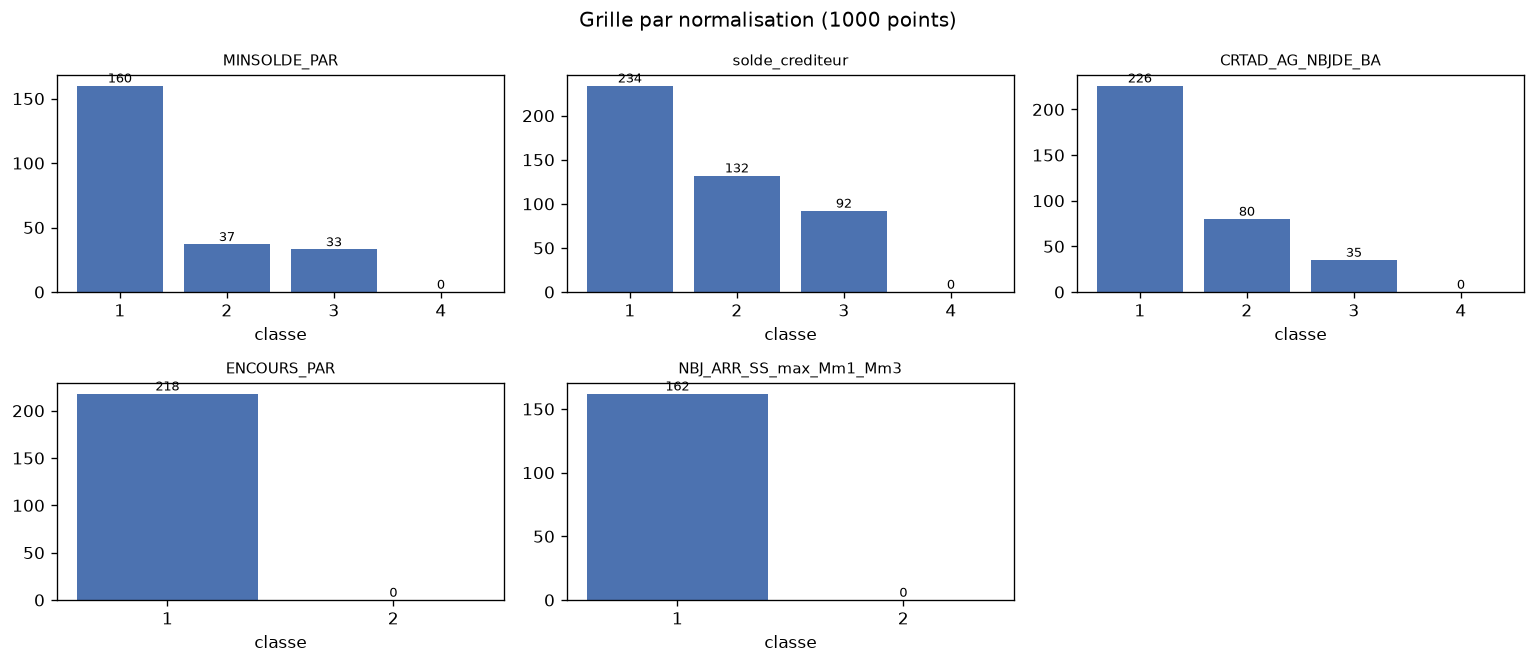

In [9]:
fig = plot_grille(grille_2, titre="Grille par normalisation (1000 points)")
plt.show()

## 6.4 Comparaison des deux méthodes

Les deux grilles sont des transformations affines décroissantes du même score linéaire : le **classement est
identique** (même Gini, même KS), et **q_j est le même** dans les deux méthodes. Les grilles sont ici arrondies au
point entier : on vérifie que l'arrondi ne coûte rien en Gini.

In [10]:
def evaluer(d, grille, nom):
    d = noter(d, grille, "points")
    return d, performance(d[TARGET], -d["points"].to_numpy(), nom)   # points élevés = moins risqué

rows = []
for nom_ech, d in (("apprentissage", df_app), ("test", df_test)):
    rows.append(performance(d[TARGET], d["S"].to_numpy(), f"score linéaire — {nom_ech}"))
    for nom_g, g in (("PDO", grille_1), ("normalisation", grille_2)):
        rows.append(evaluer(d, g, f"grille {nom_g} (arrondie) — {nom_ech}")[1])
comparaison = pl.DataFrame(rows).select("modele", "n", "n_defaut", "gini", "gini_ic_bas", "gini_ic_haut", "ks")
comparaison

modele,n,n_defaut,gini,gini_ic_bas,gini_ic_haut,ks
str,i64,i64,f64,f64,f64,f64
"""score linéaire — apprentissage""",47156,228,0.784103,0.728759,0.839448,0.651607
"""grille PDO (arrondie) — appren…",47156,228,0.783806,0.728431,0.839182,0.651892
"""grille normalisation (arrondie…",47156,228,0.784135,0.728794,0.839476,0.651607
"""score linéaire — test""",11791,56,0.744609,0.625202,0.864015,0.631161
"""grille PDO (arrondie) — test""",11791,56,0.743871,0.62433,0.863411,0.631161
"""grille normalisation (arrondie…",11791,56,0.744604,0.625197,0.864011,0.631161


In [11]:
q_pdo = contributions(grille_pdo(coefs, beta0, POINTS0, ODDS0, PDO), parts, TOTAL).select("variable", q_pdo="q")
contrib.select("variable", "CTR", q_norm="q").join(q_pdo, on="variable")

variable,CTR,q_norm,q_pdo
str,f64,f64,f64
"""ENCOURS_PAR""",21.820927,0.287193,0.287193
"""CRTAD_AG_NBJDE_BA""",22.635659,0.263966,0.263966
"""solde_crediteur""",23.357079,0.219666,0.219666
"""MINSOLDE_PAR""",15.951543,0.181419,0.181419
"""NBJ_ARR_SS_max_Mm1_Mm3""",16.234793,0.047756,0.047756


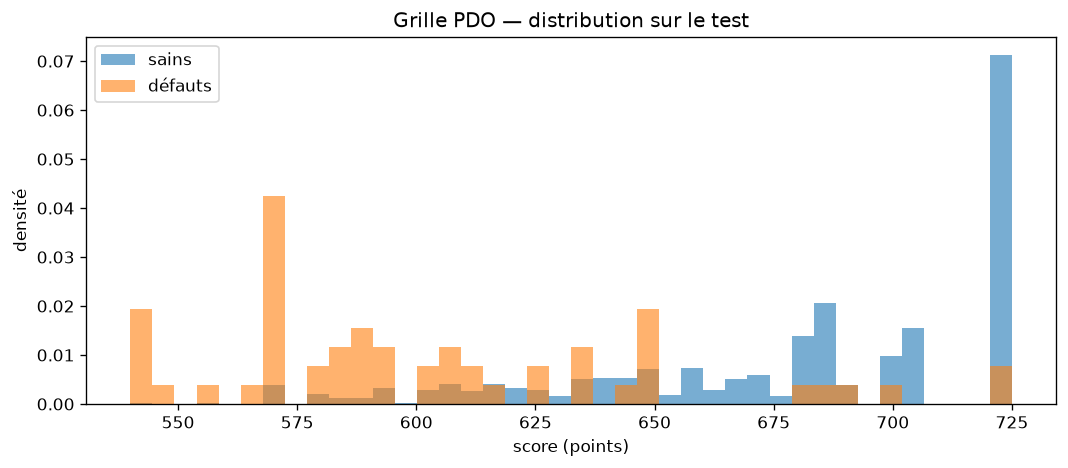

min,p5,mediane,p95,max
f64,f64,f64,f64,f64
540.0,594.0,685.0,725.0,725.0


In [12]:
test_pts, _ = evaluer(df_test, grille_1, "")
fig = plot_distribution_score(test_pts["points"], test_pts[TARGET], titre="Grille PDO — distribution sur le test")
plt.show()
test_pts.select(pl.col("points").min().alias("min"), pl.col("points").quantile(0.05).alias("p5"),
                pl.col("points").median().alias("mediane"), pl.col("points").quantile(0.95).alias("p95"),
                pl.col("points").max().alias("max"))

## Export et application à l'échantillon Out-of-Time

La grille est exportée avec tout ce qu'il faut pour noter une nouvelle base sans rien réestimer. Quand l'échantillon
OOT sera fourni :

```python
from utils.scorecard import scorer_nouvelle_base
decoupages = json.loads((ROOT / "outputs/binning/decoupages_joint.json").read_text(encoding="utf-8"))
oot = scorer_nouvelle_base(base_oot, decoupages, FUSIONS, grille_1, variables_quali=[...])
performance(oot[TARGET], -oot["score"].to_numpy(), "OOT")
```

(`variables_quali` : variables qualitatives du modèle, dont le manquant devient la modalité `"missing"` comme en `0c`.)

In [13]:
SORTIE.parent.mkdir(parents=True, exist_ok=True)
SORTIE.write_text(json.dumps({
    "parametres": {"points0": POINTS0, "odds0": ODDS0, "pdo": PDO, "total": TOTAL, "offset": offset, "factor": factor},
    "variables": VARS,
    "fusions": {v: {str(a): b for a, b in f.items()} for v, f in FUSIONS.items()},
    "grille_pdo": grille_1.to_dicts(),
    "grille_normalisation": grille_2.to_dicts(),
}, ensure_ascii=False, indent=1), encoding="utf-8")
exporter_excel({"grille_pdo": grille_1, "grille_normalisation": grille_2, "contributions": contrib,
                "comparaison": comparaison}, SORTIE_XLS)
print(f"Grille : {SORTIE}\nTables : {SORTIE_XLS}")

Grille : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\scorecard\grille_joint.json
Tables : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\scorecard\grille_joint.xlsx


## Synthèse des décisions

| § | Constat | Décision |
|---|---------|----------|
| 6.1 | score linéaire de −8,4 à 0,2 ; probabilité moyenne 0,48 % = taux de défaut observé (le modèle est centré) | ordonnancement seul utilisé ici, PD calibrée au ch. 8 |
| 6.2 PDO | Factor = 28,85, Offset = 487,1 ; classe de référence = 91 points par variable ; scores de 481 à 728 points (médiane 690 en test) | **grille PDO retenue pour la documentation** (sens en odds de chaque écart de points) |
| 6.3 Normalisation | grille de 0 à 1000 ; CTR de 3,6 % (`SOLDE_RATIO_T_vs_HIST`) à 22,1 % (`CAUSE_SAIN_M0`) | grille de pilotage interne (poids des variables) |
| 6.3 Contributions q | `CRTAD_AG_NBJDE_BA` 23 %, `ENCOURS_PAR` 22 %, `MINSOLDE_PAR` 19 %, `ANCIENNETE_modif` 12 %, `CAUSE_SAIN_M0` 9 %, `NBECR_EVOLUTION_A_vs_A1` 7 %, `NBJ_ARR_SS_max_Mm1_Mm3` 4 %, `SOLDE_RATIO_T_vs_HIST` 4 % | les trois variables de trésorerie et de patrimoine portent 64 % de la dispersion du score |
| 6.4 Comparaison | Gini identique sur le score linéaire et les deux grilles arrondies (74,8 % en test, écart < 0,02 point) ; q identique dans les deux méthodes | propriétés du cours vérifiées |

**Lecture CTR contre q** : `CAUSE_SAIN_M0` a le plus fort plafond (CTR 22 %) mais une faible contribution réelle (q 9 %) : sa
modalité risquée (retour récent au sain) est rare. À l'inverse, `ENCOURS_PAR` a un plafond moyen (14 %) mais pèse 22 % de
la dispersion, car ses deux classes sont bien peuplées.

**Ancrage** : β0 n'est pas corrigé (pas de rééchantillonnage, notebook 0 § 1.2). Les paramètres 600 / 50:1 / PDO 20 sont une
convention ; avec un taux de défaut de 0,48 % (odds de bon ≈ 207:1), 95 % des dossiers du test ont au moins 594 points.

> **Prochaine étape** : mise en classes homogènes de risque (ch. 7), à partir de la grille PDO.